In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import jv

font = {"size": 26}
plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 5

In [2]:
def DHTarrays(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    r = R * Zeroes[:N] / Zeroes[N - 1]
    k = Zeroes[:N] / R
    return np.array([r, k])

def DHTtransformMatrix(N, R, ell):
    Zeroes = np.genfromtxt("BesselZeroes" + str(ell) + ".csv")
    alpha = Zeroes[:N]
    kR = alpha[N - 1]
    kmax = kR / R
    T = (
        jv(ell, np.outer(alpha, alpha) / kR)
        / np.outer(abs(jv(ell + 1, alpha)), abs(jv(ell + 1, alpha)))
        / kR
    )
    # print(T)
    A = abs(jv(ell + 1, alpha))
    T_R2K = 4.0 * np.pi * (R / kmax) * T * A[:, None] / A[None, :]
    T_K2R = (1 / np.pi) * (kmax / R) * T * A[:, None] / A[None, :]

    return T_R2K, T_K2R

In [3]:
def forward_propagation(k, phi_I, T_R2K, T_K2R, z, zm, wavelength):
    k0 = 2 * np.pi / wavelength
    phi_R0 = phi_I * np.exp(-2j * k0 * zm) #reflected profile from mirror

    # Hankel transform the field through multiplying by the appropriate transform matrix
    FT = T_R2K @ phi_R0
    # Propagate phi_R0 over z through multiplying phi_R0 by the diffractive phase:
    FT = FT * np.exp(-1j * k**2 / (2 * k0) * z[:, np.newaxis])
    # Inverse Hankel transform 𝐸̃ from 𝑘𝑟-space to 𝑟-space through multiplying by the inverse transform matrix
    fT = T_K2R @ (FT.T)

    return fT

In [4]:
f_targ = 0.5  # focal length of lens
ell = 0  # order of Bessel J function
f_init = 0.05  # initial mirror focal length
conic = -1

# Beam Parameters
wl = 1e-6
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = 20  # f#
w0 = f_targ / (2 * fn)  # initial spot size
rmax = 1.3 * w0  # the max value of r
nr = 2000  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = 10e-2
nzf = 1000
zF = np.linspace(f_targ - 0.05, f_targ + 0.15, nzf)
fl = len(zF) // 4  # focal length index

print(rmax/nr < wR)

True


In [5]:
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

In [11]:
original=r**2/(4*f_targ)
offset=original + 1
phi_I = 1j* np.exp(-(r/w0)**16)

ftf_og=forward_propagation(k, phi_I, T_R2K, T_K2R, zF, original, wl)
ftf_off=forward_propagation(k, phi_I, T_R2K, T_K2R, zF, offset, wl)

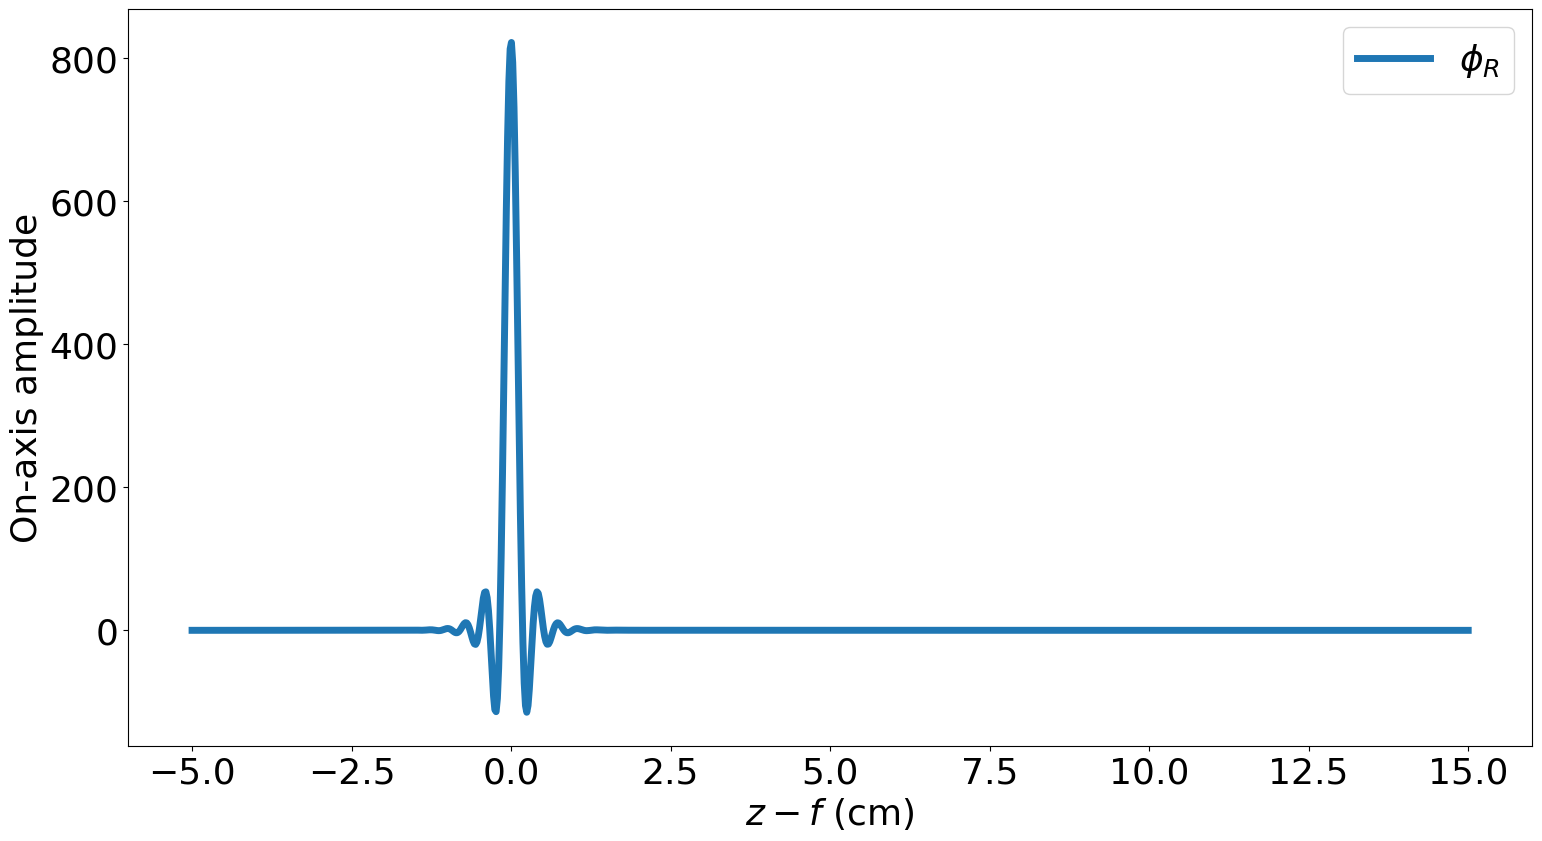

In [12]:
plt.plot((zF - f_targ) * 100 , np.real(ftf_og[0, :]), label=r"$\phi_R$")
# plt.plot((zF - f_targ) * 100, np.real(ftf_off[0, :]), label=r"$\phi_R+1$ m", linestyle="--")
plt.ylabel("On-axis amplitude")
plt.xlabel(r"$z-f$ (cm)")
plt.legend()
#     plt.show()
plt.tight_layout()
# plt.savefig("offset_on_axis_1m.png")

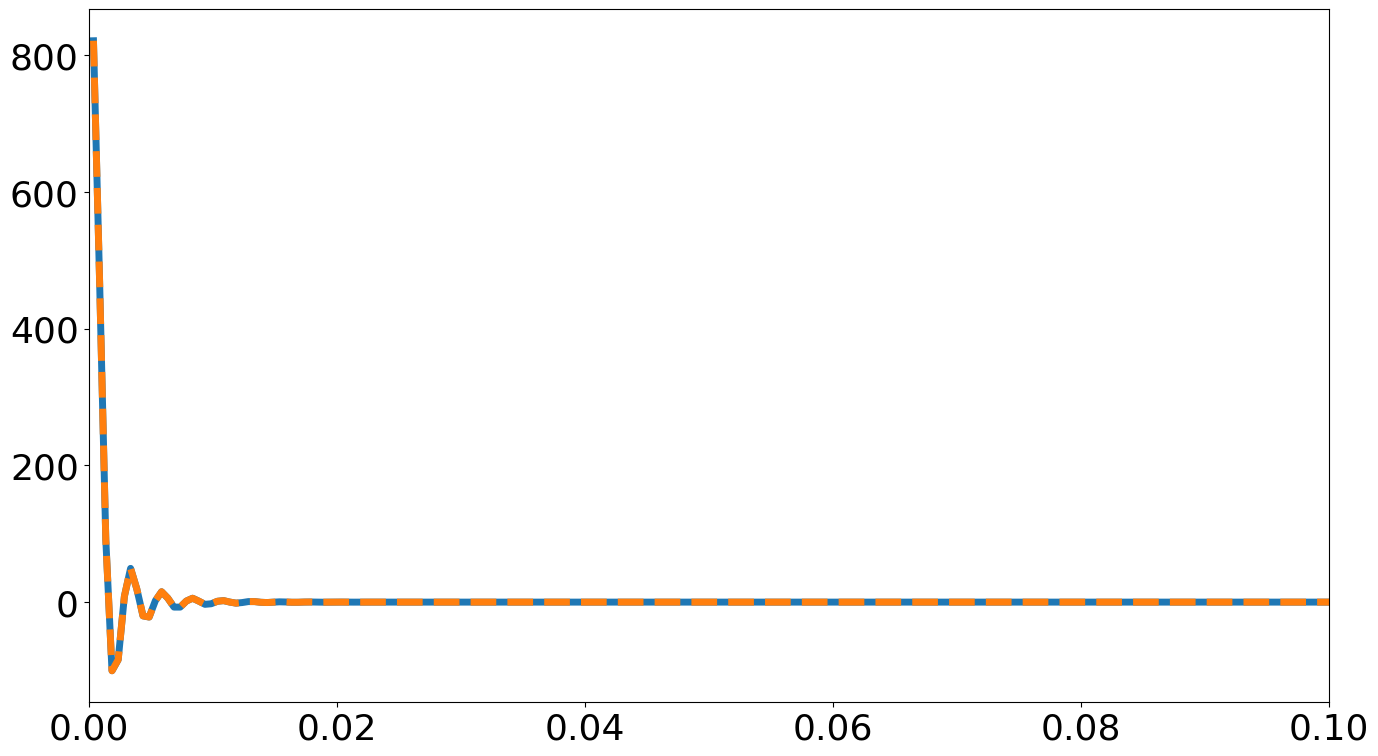

In [13]:
plt.plot(r/rmax, np.real(ftf_og[:, fl]), label=r"$\phi_R$")
plt.plot(r/rmax, np.real(ftf_off[:,fl]), label=r"$\phi_R+1$ m", linestyle="--")
plt.xlim(0,0.1)
plt.show()